In [9]:
import os
import sys
from pathlib import Path

DIRPATH_REPO = Path().resolve().parents[0]
sys.path.append(str(DIRPATH_REPO))
print(DIRPATH_REPO)

import matplotlib.pyplot as plt
import numpy as np

from rate_model import RateModelLin, RateModelWC
from transfer_mat import TransferMatBuider

#ARTIFACT_DIR = Path(__file__).resolve().parent / 'artifacts' / 'rate_model_ker'
#ARTIFACT_PATH = ARTIFACT_DIR / 'rate_model_kernel_syn_demo.png'

/home/nnovikov/repo/resp_predictor


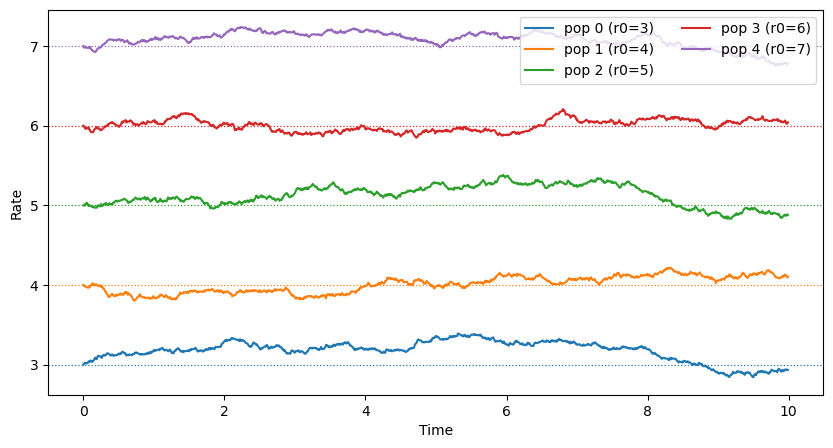

In [27]:
#np.random.seed(123)

# Target operating point
r0 = np.array([3, 4, 5, 6, 7]).reshape(-1, 1)
n_pop = r0.shape[0]

# Model parameters
#tau = np.linspace(0.4, 1.8, n_pop).reshape(-1, 1)
tau = 1

# Model type
#model_type = 'lin'
model_type = 'wc'

# Create model
if model_type == 'lin':
    model, h0, J = RateModelLin.from_steady_state(
        r0=r0, tau=tau, R=0.5)
elif model_type == 'wc':
    model, h0, J = RateModelWC.from_steady_state(
        r0=r0, tau=tau, R=0.5, rmax=10, gain_slope=0.5, gain_center=0)

# Simulation params
T = 10
dt = 0.01
nsteps = int(T / dt)

# Add input noise
sigma_h = 0.1
H = h0 + sigma_h * np.random.randn(n_pop, nsteps) / np.sqrt(dt)

# Run model
rr = model.run(H, r0, dt=dt, nsteps=nsteps)

fig, ax = plt.subplots(1, 1, figsize=(10, 5))
for pop in range(n_pop):
    ax.plot(rr.time, rr.isel(pop=pop), label=f'pop {pop} (r0={r0[pop, 0]:.0f})')
    ax.axhline(r0[pop, 0], color=f'C{pop}', linestyle=':', linewidth=0.9)

ax.set_xlabel('Time')
ax.set_ylabel('Rate')
ax.legend(loc='upper right', ncol=2)


In [28]:
tmb = TransferMatBuider(
    model, freqs=[5], amps=[1, 5, 10], h0=h0, dt=dt, sigma_h=sigma_h
)
R1 = tmb.compute_input_traces()
D = tmb.compute_input_gains()
C = tmb.compute_transfer_mat()

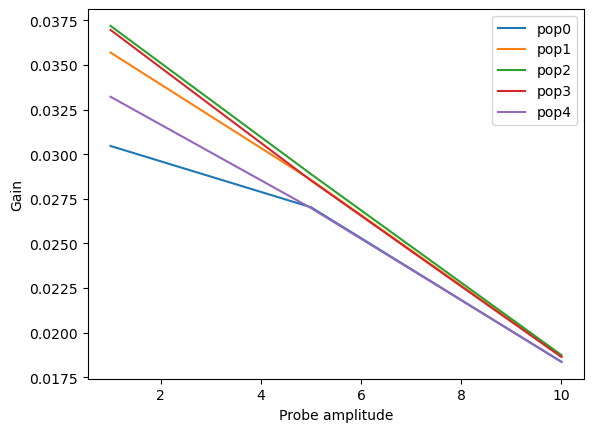

In [29]:
plt.figure()
for pop in D.pop.values:
    dd = D.sel(pop=pop).squeeze(drop=True)
    plt.plot(D.amp, np.abs(dd), label=f'pop{pop}')
plt.xlabel('Probe amplitude')
plt.ylabel('Gain')
plt.legend()

(5.0, 7.0)

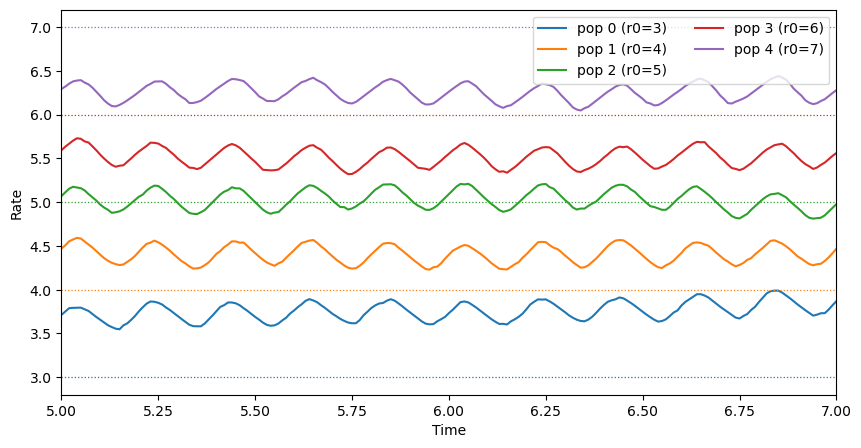

In [32]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
for pop in range(n_pop):
    tt, rr = R1.time, R1.isel(pop_pre=pop, amp=1).squeeze(drop=True)
    ax.plot(tt, rr, label=f'pop {pop} (r0={r0[pop, 0]:.0f})')
    ax.axhline(r0[pop, 0], color=f'C{pop}', linestyle=':', linewidth=0.9)
ax.set_xlabel('Time')
ax.set_ylabel('Rate')
ax.legend(loc='upper right', ncol=2)
ax.set_xlim(5, 7)

In [23]:
#C = tmb.compute_transfer_mat()
print((C.squeeze(drop=True)).round(2))

<xarray.DataArray (pop_pre: 5, pop_post: 5, amp: 3)> Size: 1kB
array([[[-0.03-0.07j,  0.01-0.06j,  0.02-0.07j],
        [ 0.01-0.j  ,  0.01+0.j  , -0.  +0.01j],
        [-0.01+0.01j, -0.  +0.01j, -0.  +0.01j],
        [-0.01-0.03j,  0.  -0.01j,  0.  -0.01j],
        [-0.  +0.j  , -0.  -0.j  , -0.  +0.j  ]],

       [[-0.01+0.05j,  0.  -0.01j,  0.  -0.j  ],
        [-0.06-0.03j,  0.01-0.01j,  0.01-0.01j],
        [-0.03-0.j  ,  0.  -0.j  , -0.  +0.01j],
        [-0.  -0.j  ,  0.  +0.j  ,  0.  +0.01j],
        [-0.01-0.01j, -0.  +0.j  ,  0.  +0.01j]],

       [[-0.05-0.01j, -0.03-0.04j,  0.  -0.j  ],
        [-0.01+0.04j, -0.01-0.j  , -0.  +0.01j],
        [-0.02+0.05j,  0.  +0.01j,  0.  +0.01j],
        [-0.03-0.03j,  0.  -0.01j,  0.01-0.01j],
        [-0.01-0.04j, -0.  -0.01j,  0.  -0.01j]],

       [[ 0.09-0.21j,  0.01-0.01j,  0.03-0.01j],
        [-0.01-0.09j,  0.02-0.04j,  0.02-0.02j],
        [-0.02+0.j  ,  0.01+0.01j,  0.  +0.03j],
        [ 0.02-0.03j,  0.  -0.j  , -0.01+0.01j],
